# Freight Rate Prediction

## 0. Setup
Imports, file paths, and random seed for reproducibility.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
SEED = 42
DATA_DIR = 'data/'
train_test_file = 'train_test.csv'
dec_chart_file = 'december_chart_inputs.csv'
val_file = 'validation.csv'
val_template_file = 'validation_predictions_template.csv'

In [3]:
df_train_test = pd.read_csv(DATA_DIR+train_test_file, parse_dates=['date'])
df_train_test.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [4]:
df_val = pd.read_csv(DATA_DIR+val_file, parse_dates=['date'])
df_val.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [5]:
df_dec_chart = pd.read_csv(DATA_DIR+dec_chart_file, parse_dates=['date'])
df_dec_chart.head(5)

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,810.140537
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,818.286686
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,820.377664
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,819.736636
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,820.999536


In [6]:
df_val_template = pd.read_csv(DATA_DIR+val_template_file)
df_val_template.head(5)

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN


## 1. Data Overview
Load the three datasets and check shape, columns, date ranges, missing values, duplicates, and category coverage.


In [7]:
# Section 1 setup: all datasets in one place
datasets = {
    'train_test': df_train_test,
    'validation': df_val,
    'december_chart': df_dec_chart,
    'val_template': df_val_template,
}

### 1.1 Shape and data types

In [8]:
shape_rows = []
for name, df in datasets.items():
    shape_rows.append({'dataset': name, 'rows': df.shape[0], 'columns': df.shape[1]})

pd.DataFrame(shape_rows)

,dataset,rows,columns
0,train_test,48000,14
1,validation,12000,13
2,december_chart,31,7
3,val_template,12000,2


In [9]:
# Data types side by side (NaN = column not present in that dataset)
pd.DataFrame({name: df.dtypes for name, df in datasets.items()})

,train_test,validation,december_chart,val_template
date,datetime64[us],datetime64[us],datetime64[us],NaN
delivery,str,str,str,NaN
delivery_lat,float64,float64,NaN,NaN
delivery_lon,float64,float64,NaN,NaN
distance,float64,float64,int64,NaN
equipment,str,str,str,NaN
load_id,str,str,NaN,str
market_index,float64,float64,NaN,NaN
pickup,str,str,str,NaN
pickup_lat,float64,float64,NaN,NaN


In [10]:
print('In train, not in validation:', set(df_train_test.columns) - set(df_val.columns))
print('In train, not in December:  ', set(df_train_test.columns) - set(df_dec_chart.columns))

In train, not in validation: {'posted_rate'}
In train, not in December:   {'delivery_lon', 'posted_rate', 'load_id', 'pickup_lon', 'pickup_lat', 'delivery_lat', 'market_index', 'quote_signal'}


### 1.2 Date ranges

In [11]:
date_rows = []
for name, df in datasets.items():
    if 'date' in df.columns:
        date_rows.append({
            'dataset': name,
            'min_date': df['date'].min(),
            'max_date': df['date'].max(),
        })

pd.DataFrame(date_rows)

,dataset,min_date,max_date
0,train_test,2025-01-01,2025-10-31
1,validation,2025-11-01,2025-12-31
2,december_chart,2025-12-01,2025-12-31


### 1.3 Missing values

In [12]:
missing_cols = {}
for name, df in datasets.items():
    nulls = df.isnull().sum()
    missing_cols[name] = nulls[nulls > 0]

pd.DataFrame(missing_cols)

,train_test,validation,december_chart,val_template
market_index,374.0,249.0,NaN,NaN
predicted_rate,NaN,NaN,NaN,12000.0
weight,300.0,165.0,NaN,NaN


### 1.4 Duplicates

In [13]:
df_train_test.duplicated().sum()

np.int64(0)

In [14]:
dups_cols = {}
for name, df in datasets.items():
    cols = set(df.columns) - set(['load_id'])
    dups = df.duplicated(cols).sum()
    dups_cols[name] = dups

pd.Series(dups_cols)

train_test            0
validation            0
december_chart        0
val_template      11999
dtype: int64

### 1.5 Categories and coverage

In [15]:
categories = {}
coverage = {}
for name, df in datasets.items():
    categories[name] = df.nunique()

pd.DataFrame(categories)

,train_test,validation,december_chart,val_template
date,304.0,61.0,31.0,NaN
delivery,64.0,72.0,1.0,NaN
delivery_lat,64.0,72.0,NaN,NaN
delivery_lon,63.0,71.0,NaN,NaN
distance,21204.0,9309.0,1.0,NaN
equipment,3.0,3.0,1.0,NaN
load_id,48000.0,12000.0,NaN,12000.0
market_index,32884.0,9520.0,NaN,NaN
pickup,64.0,72.0,1.0,NaN
pickup_lat,64.0,72.0,NaN,NaN


In [16]:
#Coverage shows which cities and lanes in validation and December never appear in train, meaning the model has no history for them
def get_values(df, col):
    """Return a column, or build the lane (pickup -> delivery) on the fly."""
    if col == 'lane':
        return df['pickup'] + ' -> ' + df['delivery']
    return df[col]

coverage_rows = []
for name in ['validation', 'december_chart']:
    df = datasets[name]
    for col in ['pickup', 'delivery', 'equipment', 'lane']:
        train_values = set(get_values(df_train_test, col).unique())
        target_values = get_values(df, col)
        unseen = set(target_values.unique()) - train_values

        coverage_rows.append({
            'dataset': name,
            'column': col,
            'unseen_values': len(unseen),
        })

pd.DataFrame(coverage_rows)

,dataset,column,unseen_values
0,validation,pickup,8
1,validation,delivery,8
2,validation,equipment,0
3,validation,lane,736
4,december_chart,pickup,0
5,december_chart,delivery,0
6,december_chart,equipment,0
7,december_chart,lane,0


### 1.6 Descriptive statistics

In [17]:
df_train_test.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.399999,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


In [18]:
df_val.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,12000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,2025-12-01 02:30:28.800000,0.926913,2.051334
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,2025-11-01 00:00:00,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,2025-11-16 00:00:00,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,2025-12-01 00:00:00,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,2025-12-16 00:00:00,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,2025-12-31 00:00:00,1.098950,2.896350
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,NaN,0.074109,0.219804


## 2. Exploratory Data Analysis
Distributions of the target and key features, relationships between rate and distance, equipment, lanes, and time.


### 2.1 Target distribution

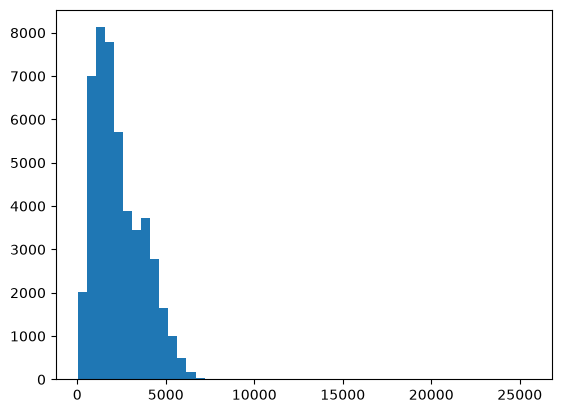

In [19]:
plt.hist(df_train_test['posted_rate'], bins=50);

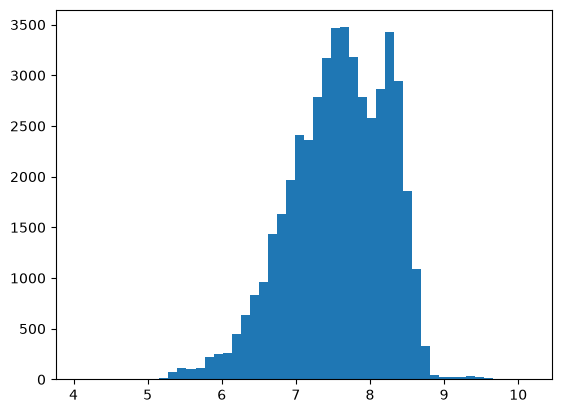

In [20]:
plt.hist(np.log1p(df_train_test['posted_rate']), bins=50);

Target is right-skewed with a long tail; log scale shows two modes and isolated extremes on both ends

### 2.2 Rate vs distance

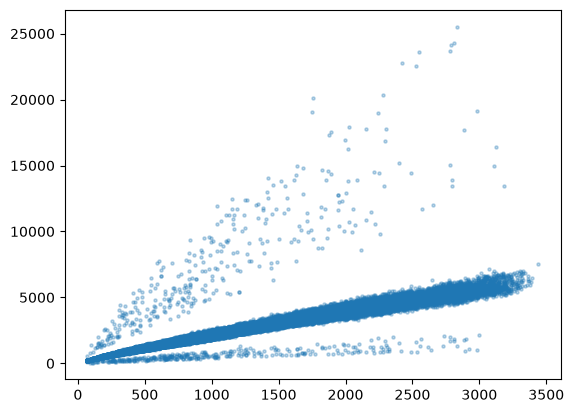

In [21]:
plt.scatter(df_train_test['distance'], df_train_test['posted_rate'], s=5, alpha=0.3)
plt.show()

Rate is roughly linear in distance. Two anomalous groups: a lower band (likely a systematic recording error) and scattered high outliers

### 2.3 Rate by equipment

In [22]:
df_train_test['rate_per_mile'] = df_train_test['posted_rate']/df_train_test['distance']

<Axes: title={'center': 'rate_per_mile'}, xlabel='equipment'>

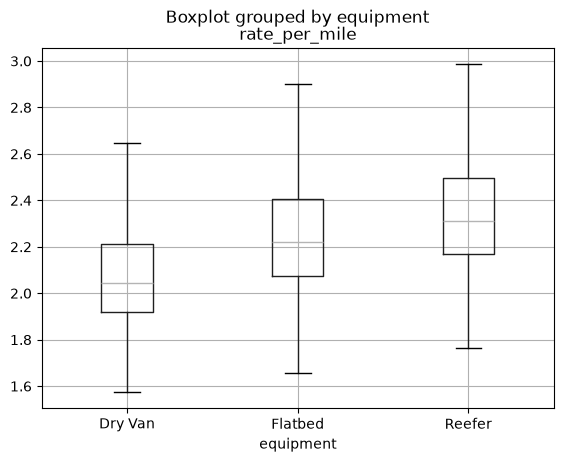

In [23]:
df_train_test.boxplot(column = 'rate_per_mile', by='equipment', showfliers=False)

Reefer has the highest median rate per mile, followed by Flatbed and Dry Van. The difference is around 0.25 $/mile, which adds up on long loads, so equipment is a useful feature. Outliers are hidden here to make the comparison readable.

### 2.4 Rate over time

<Axes: xlabel='date'>

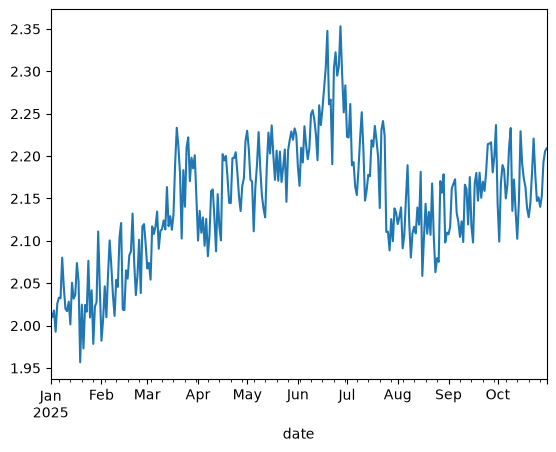

In [25]:
df_train_test.groupby('date')['rate_per_mile'].median().plot()

Rate per mile rises from January to a late-June peak, drops in July, then stabilizes. Short-term oscillation suggests a day-of-week effect.

### 2.5 Quote signal vs actual rate per mile

[]

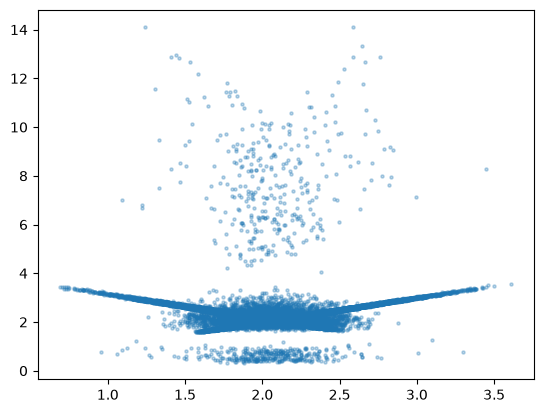

In [26]:
plt.scatter(df_train_test['quote_signal'], df_train_test['rate_per_mile'], s=5, alpha=0.3)
plt.plot()

The relationship between quote signal and rate per mile is V-shaped. Above ~2.5, rate rises with the quote as expected. Below ~1.6, rate rises as the quote falls, which is the opposite of how a price quote should behave. The rate outliers (above 4 and below 1) appear at every quote level, so they come from the rate, not the quote.

In [27]:
left_arm = df_train_test[
    (df_train_test['quote_signal'] < 1.6) &
    (df_train_test['rate_per_mile'] > 1.5) &
    (df_train_test['rate_per_mile'] < 4)
]

(left_arm['quote_signal'] + left_arm['rate_per_mile']).describe()

count    2270.000000
mean        4.119734
std         0.138150
min         3.158420
25%         4.122771
50%         4.144800
75%         4.165046
max         4.562847
dtype: float64

In the left arm (quote < 1.6, normal rates), quote + rate per mile is nearly constant: median 4.14, with the middle 50% between 4.12 and 4.17 across 2,270 rows (~5% of train). This suggests the quote signal is mirrored in this region. A tree-based model can learn this pattern; correcting it explicitly (4.14 − quote) is a possible improvement.

In [28]:
df_train_test['quote_signal'].describe()

count    48000.000000
mean         2.062468
std          0.291391
min          0.692280
25%          1.891030
50%          2.055750
75%          2.221685
max          3.610350
Name: quote_signal, dtype: float64

### 2.6 Key findings

- **Target:** posted rate is right-skewed with a long tail; rate scales roughly linearly with distance, so rate per mile is used as the modeling target.
- **Outliers:** 669 loads have a rate per mile below 1 or above 4, while only 10 fall between 1–1.5 or 3.5–4. These isolated groups point to recording errors.
- **Equipment:** Reefer > Flatbed > Dry Van in median rate per mile, with a difference of around 0.25 $/mile.
- **Time:** rate per mile rises to a late-June peak, drops in July, and stabilizes from August to October, with short-term oscillation suggesting a day-of-week effect. This supports a time-based split.
- **Quote signal:** loosely related to rate in its normal range (~1.6–2.5), so route, equipment and date features are needed; V-shaped overall, with a mirrored region below ~1.6 (quote + rate ≈ 4.14). Favors a non-linear model.

## 3. Data Cleaning
Handle data-quality issues found in sections 1 and 2. Each decision is documented with its rationale.


### 3.1 Negative weights

In [29]:
print('Negative weights in train:', (df_train_test['weight'] < 0).sum())
print('Negative weights in validation:', (df_val['weight'] < 0).sum())

Negative weights in train: 292
Negative weights in validation: 145


In [30]:
print(df_train_test.loc[df_train_test['weight'] < 0, 'weight'].abs().describe())
print()
print(df_train_test.loc[df_train_test['weight'] > 0, 'weight'].describe())

count      292.000000
mean     31724.195205
std       8262.536326
min       5000.000000
25%      25928.500000
50%      31821.500000
75%      37284.250000
max      47500.000000
Name: weight, dtype: float64

count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64


In [31]:
for df in [df_train_test, df_val]:
    df['weight'] = df['weight'].abs()

In [32]:
print('Negative weights in train:', (df_train_test['weight'] < 0).sum())
print('Negative weights in validation:', (df_val['weight'] < 0).sum())

Negative weights in train: 0
Negative weights in validation: 0


292 train and 145 validation loads have negative weights. Their absolute values follow the same distribution as the positive weights (median ~31.8k vs ~31.5k, same min and max), so this is a sign error. Fixed by taking the absolute value.

### 3.2 Missing values

In [33]:
print(df_train_test[['weight', 'market_index']].isna().sum())
print(df_val[['weight', 'market_index']].isna().sum())

weight          300
market_index    374
dtype: int64
weight          165
market_index    249
dtype: int64


In [34]:
for df in [df_train_test, df_val]:
    df['weight_missing'] = df['weight'].isna().astype(int)
    df['market_index_missing'] = df['market_index'].isna().astype(int)

Weight is missing for 300 train and 165 validation loads, and market_index for 374 and 249. Rows can’t be dropped from validation, so missing indicators are added here. Values will be filled with the training-set median after the split, to avoid leakage.

### 3.3 Extreme rates

In [75]:
bins = [0, 1, 1.5, 3.5, 4, 100]
labels = ['0-1', '1-1.5', '1.5-3.5', '3.5-4', '4+']
pd.cut(df_train_test['rate_per_mile'], bins=bins, labels=labels).value_counts().sort_index()

rate_per_mile
0-1            0
1-1.5          8
1.5-3.5    47321
3.5-4          2
4+             0
Name: count, dtype: int64

Almost no loads fall between 1–1.5 or 3.5–4 $/mile (10 in total), so the 669 loads below 1 or above 4 are isolated from the normal range. These are treated as recording errors in the cleaning step.

In [35]:
rows_before = len(df_train_test)

df_train_test = df_train_test[
    (df_train_test['rate_per_mile'] >= 1) &
    (df_train_test['rate_per_mile'] <= 4)
]

print('Rows removed:', rows_before - len(df_train_test))
print('Rows remaining:', len(df_train_test))

Rows removed: 669
Rows remaining: 47331


Loads with a rate per mile below 1 or above 4 are removed from training, based on the range table above. This only applies to train; validation loads are kept, since every one needs a prediction.

### 3.4 Data types alignment

In [36]:
print(df_dec_chart.dtypes)
df_dec_chart['distance'] = df_dec_chart['distance'].astype(float)
df_dec_chart['weight'] = df_dec_chart['weight'].astype(float)
print(df_dec_chart.dtypes)

pickup                       str
delivery                     str
distance                   int64
equipment                    str
weight                     int64
date              datetime64[us]
predicted_rate           float64
dtype: object
pickup                       str
delivery                     str
distance                 float64
equipment                    str
weight                   float64
date              datetime64[us]
predicted_rate           float64
dtype: object


In the December file, distance and weight are stored as integers, while train and validation use floats. They are cast to float for consistency across datasets.

## 4. Train/Test Split
Time-based split that mirrors the validation scenario: train on earlier months, test on the most recent ones.


In [37]:
split_date = '2025-09-01'

train = df_train_test[df_train_test['date']<split_date]
test = df_train_test[df_train_test['date']>split_date]

print('Train:', train.shape, train['date'].min().date(), 'to', train['date'].max().date())
print('Test: ', test.shape, test['date'].min().date(), 'to', test['date'].max().date())

Train: (37951, 17) 2025-01-01 to 2025-08-31
Test:  (9224, 17) 2025-09-02 to 2025-10-31


Validation contains future loads (November–December), so the split mirrors that: January–August for training and September–October for testing. A random split would mix months and give an overly optimistic evaluation.

In [38]:
weight_median = train['weight'].median()
market_index_median = train['market_index'].median()

for df in [train, test, df_val]:
    df['weight'] = df['weight'].fillna(weight_median)
    df['market_index'] = df['market_index'].fillna(market_index_median)

for name, df in [('train', train), ('test', test), ('validation', df_val)]:
    print(name, df[['weight', 'market_index']].isna().sum().to_dict())

train {'weight': 0, 'market_index': 0}
test {'weight': 0, 'market_index': 0}
validation {'weight': 0, 'market_index': 0}


Missing weight and market_index values are filled with the training-set median, applied to train, test and validation. The missing indicators created in section 3.2 keep track of which values were imputed.

## 5. Feature Engineering
Date features, lane features, and target transformation. Statistics that learn from data are fitted on the training set only.


### 5.1 Target: rate per mile

The model predicts rate per mile (posted_rate / distance). Final predictions are converted back to a total rate by multiplying by distance.

### 5.2 Date features

In [39]:
def add_date_features(df):
    df['day_of_week'] = df['date'].dt.dayofweek
    df['day_of_month'] = df['date'].dt.day
    return df

for df in [train, test, df_val, df_dec_chart]:
    add_date_features(df)

train.columns

Index(['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon',
       'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight',
       'date', 'market_index', 'quote_signal', 'posted_rate', 'rate_per_mile',
       'weight_missing', 'market_index_missing', 'day_of_week',
       'day_of_month'],
      dtype='str')

Day of week captures the weekly oscillation seen in the EDA. Month is left out because validation months (November and December) never appear in training, so the model couldn’t learn from them.

### 5.3 Lane features

In [40]:
for df in [train, test, df_val, df_dec_chart]:
    df['lane'] = df['pickup'] + ' -> ' + df['delivery']

lane_median = train.groupby('lane')['rate_per_mile'].median()
global_median = train['rate_per_mile'].median()

for df in [train, test, df_val, df_dec_chart]:
    df['lane_median_rpm'] = df['lane'].map(lane_median).fillna(global_median)
    df['lane_known'] = df['lane'].isin(lane_median.index).astype(int)

In [ ]:
print('Share of validation loads on known lanes:', df_val['lane_known'].mean().round(3))
df_val[['lane', 'lane_median_rpm', 'lane_known']].drop_duplicates('lane_known')

Share of validation loads on known lanes: 0.877


,lane,lane_median_rpm,lane_known
0,Baton Rouge -> Mobile,2.629333,1
9,Norfolk -> Columbia,2.141114,0


Lane median rate per mile captures how much each route typically pays. It is computed on the training set only. About 12% of validation loads are on lanes unseen in training; for those, the global median is used, and a lane_known flag tells the model the value is a fallback.

### 5.4 Feature sets for Model A and Model B

In [42]:
features_b = [
    'distance', 'weight', 'equipment',
    'day_of_week', 'day_of_month',
    'lane_median_rpm', 'lane_known',
]

features_a = features_b + [
    'market_index', 'market_index_missing',
    'quote_signal', 'weight_missing',
]

for df in [train, test, df_val, df_dec_chart]:
    df['equipment'] = df['equipment'].astype('category')

Model B uses only features available in the December file. Model A adds market_index, quote_signal and the missing indicators. Comparing both shows how much the extra signals add, and decides which model is delivered.

## 6. Baselines
Simple non-ML references to beat, such as the quote signal multiplied by distance.


### 6.1 Quote signal baseline & 6.2 Lane median baseline

In [43]:
from sklearn.metrics import mean_absolute_error

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mape = (abs(y_true-y_pred)/y_true).mean()*100
    print(f'{name}: MAE ${mae:,.0f} | MAPE {mape:.1f}%')

MAE on the total rate is used as the main metric, since it reads directly as dollars of error per load. Two simple baselines set the bar for the models: quote signal × distance, and lane median rate per mile × distance.

In [44]:
evaluate('Baseline - quote signal', test['posted_rate'], test['quote_signal'] * test['distance'])
evaluate('Baseline - lane median', test['posted_rate'], test['lane_median_rpm'] * test['distance'])

Baseline - quote signal: MAE $195 | MAPE 10.0%
Baseline - lane median: MAE $139 | MAPE 5.8%


The lane median baseline (MAE $139, 5.8%) beats the quote signal baseline ($195, 10.0%), partly because of the mirrored quote region found in the EDA. The models need to beat $139.

## 7. Model Comparison
Model A (all features) vs Model B (December-compatible features), compared against the baselines.


In [45]:
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

### 7.1 LightGBM

In [56]:
results = []

def fit_and_score(model_name, model, fs_name, features):
    X_train = pd.get_dummies(train[features], columns=['equipment'])
    X_test = pd.get_dummies(test[features], columns=['equipment'])
    model.fit(X_train, train['rate_per_mile'])
    pred_rate = model.predict(X_test) * test['distance']
    evaluate(f'{model_name} - {fs_name}', test['posted_rate'], pred_rate)
    results.append({
        'model': model_name,
        'features': fs_name,
        'MAE ($)': round(mean_absolute_error(test['posted_rate'], pred_rate)),
    })
    return model, pred_rate

In [57]:
lgbm_a, pred_lgbm_a = fit_and_score('LightGBM', LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1), 'A', features_a)
lgbm_b, pred_lgbm_b = fit_and_score('LightGBM', LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1), 'B', features_b)

LightGBM - A: MAE $80 | MAPE 3.2%
LightGBM - B: MAE $73 | MAPE 3.2%


### 7.2 Random Forest

In [58]:
rf_a, pred_rf_a = fit_and_score('Random Forest', RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED), 'A', features_a)
rf_b, pred_rf_b = fit_and_score('Random Forest', RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED), 'B', features_b)

Random Forest - A: MAE $56 | MAPE 2.3%
Random Forest - B: MAE $55 | MAPE 2.4%


In [74]:
feature_names = pd.get_dummies(train[features_b], columns=['equipment']).columns
importance = pd.Series(rf_b.feature_importances_, index=feature_names).sort_values(ascending=False)
importance

lane_median_rpm      0.691707
equipment_Dry Van    0.149376
weight               0.057902
distance             0.057344
day_of_month         0.020112
day_of_week          0.012341
equipment_Flatbed    0.005792
equipment_Reefer     0.005426
lane_known           0.000000
dtype: float64

### 7.3 Ridge

In [59]:
ridge_a, pred_ridge_a = fit_and_score('Ridge', Ridge(), 'A', features_a)
ridge_b, pred_ridge_b = fit_and_score('Ridge', Ridge(), 'B', features_b)

Ridge - A: MAE $108 | MAPE 4.5%
Ridge - B: MAE $66 | MAPE 2.8%


### 7.4 Results and model selection

In [60]:
pd.DataFrame(results).sort_values('MAE ($)')

,model,features,MAE ($)
3,Random Forest,B,55
2,Random Forest,A,56
5,Ridge,B,66
1,LightGBM,B,73
0,LightGBM,A,80
4,Ridge,A,108


Random Forest performs best with both feature sets ($55 with B, $56 with A). Feature set B is as good as or better than A for every model, so market_index and quote_signal don’t add value on the test period. Ridge with set A performs worst ($108), consistent with the non-linear quote signal pattern found in the EDA. Random Forest with feature set B is selected: best performance, and it works directly on the December file.

**Note**: hyperparameter tuning was skipped due to the time limit. All models use default or simple settings, so the ranking could change with tuning, especially for LightGBM.

## 8. Final Evaluation
One-time evaluation of the selected model on the held-out test set.


In [65]:
test_eval = test.assign(pred=pred_rf_b, abs_error=(test['posted_rate'] - pred_rf_b).abs())

print(test_eval.groupby('lane_known')['abs_error'].mean().round(0))
print(test_eval.groupby('equipment', observed=True)['abs_error'].mean().round(0))

lane_known
0    90.0
1    54.0
Name: abs_error, dtype: float64
equipment
Dry Van    48.0
Flatbed    67.0
Reefer     60.0
Name: abs_error, dtype: float64


The test set was also used to select the model, so this is a slightly optimistic estimate. Error on unseen lanes ($90) is much higher than on known lanes ($54), since the lane median falls back to the global value; this is the model's main weakness. By equipment, Dry Van has the lowest error ($48), followed by Reefer ($60) and Flatbed ($67).

## 9. Final Training and Predictions
Retrain on all development data and generate predictions for validation and December.


### 9.1 Retrain on full development data

In [66]:
full = pd.concat([train, test])

def to_X(df):
    return pd.get_dummies(df[features_b], columns=['equipment'])

X_full = to_X(full)

final_model = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED)
final_model.fit(X_full, full['rate_per_mile'])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

The selected model, Random Forest with feature set B, is retrained on all development data (January–October), so it learns from the most recent months before predicting November and December. Lane medians are recomputed on the full data, and equipment is one-hot encoded with fixed categories so all files share the same columns.

### 9.2 Validation predictions

In [69]:
df_val['predicted_rate'] = final_model.predict(
    to_X(df_val).reindex(columns=X_full.columns, fill_value=0)
) * df_val['distance']

submission = df_val_template[['load_id']].merge(
    df_val[['load_id', 'predicted_rate']], on='load_id', how='left'
)
submission.to_csv('validation_predictions.csv', index=False)

print('Rows:', len(submission))
print('Missing predictions:', submission['predicted_rate'].isna().sum())
print('Non-positive predictions:', (submission['predicted_rate'] <= 0).sum())

Rows: 12000
Missing predictions: 0
Non-positive predictions: 0


Predictions are made in rate per mile, converted to total rate by multiplying by distance, and matched to the template by load_id.

### 9.3 December predictions

In [70]:
dec_output = pd.read_csv(DATA_DIR + dec_chart_file)
dec_output['predicted_rate'] = final_model.predict(
    to_X(df_dec_chart).reindex(columns=X_full.columns, fill_value=0)
) * df_dec_chart['distance']
dec_output.to_csv(DATA_DIR + dec_chart_file, index=False)

dec_output[['date', 'predicted_rate']].head()

,date,predicted_rate
0,2025-12-01,806.967928
1,2025-12-02,814.633460
2,2025-12-03,817.229444
3,2025-12-04,817.808676
4,2025-12-05,817.276244


December predictions are added to the original file, keeping its seven columns unchanged, as required by score.py.

## 10. Scoring and December Chart
Run score.py and interpret the December chart.


In [72]:
import sys
!"{sys.executable}" score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.


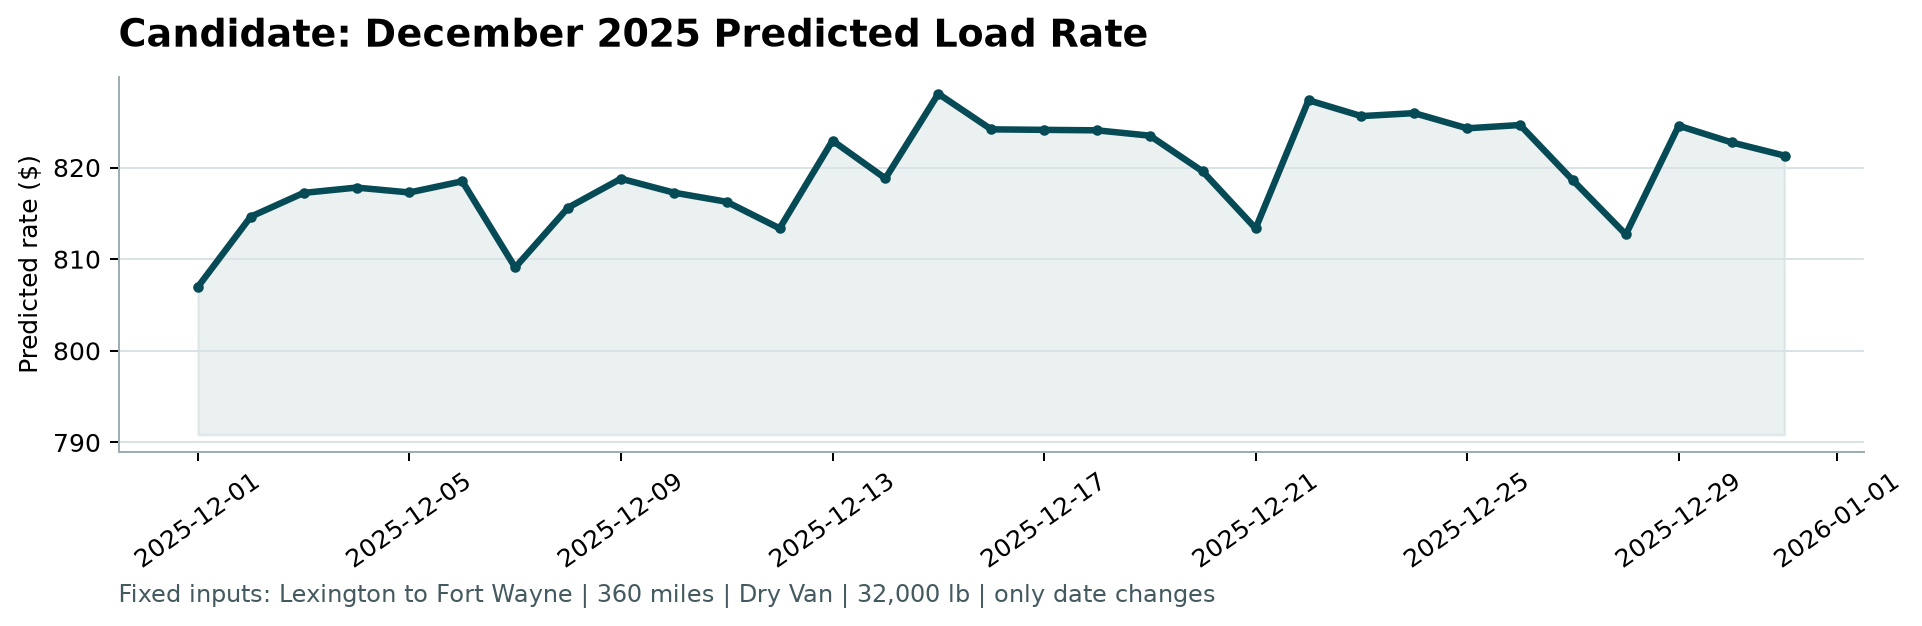

In [73]:
from IPython.display import Image
Image('scorer_results/candidate_december.png')

Both files pass score.py validation. The December chart shows predictions between roughly \$807 and \$828 for the same load, about 2.28 \$/mile, consistent with the August–October level seen in the EDA. The small, roughly weekly dips come from the day-of-week feature. There is no holiday effect around Christmas or New Year: the model never saw December in training and has no holiday features, so this is a known limitation.

## 11. Conclusions
Key findings, limitations, and next steps with more time.

## 11. Conclusions

**Final model:** Random Forest with December-compatible features (feature set B), predicting rate per mile. On the September–October test set it reaches a mean absolute error of $55 per load (2.4%), compared with $139 for the best simple baseline.

**Key findings**
- Rate per mile is used as the target, since total rate scales almost linearly with distance (section 2.2).
- The data had several quality issues: negative weights (sign errors), missing values, isolated extreme rates, and a quote signal that appears mirrored below ~1.6.
- The lane median rate per mile is the most important feature in the final model (~69% of feature importance, section 7). market_index and quote_signal did not improve test performance.

**Limitations**
- The test set was used for model selection, so the $55 error is slightly optimistic.
- Error is much higher on unseen lanes ($90 vs $54), and about 12% of validation loads are on lanes not seen in training.
- The lane_known flag is always 1 in training, so the model can't learn from it; unseen lanes rely only on the global median fallback.
- The model has no holiday or month features, so it can't capture December-specific effects.
- No hyperparameter tuning was performed.

**Next steps with more time**
- Add city-level or regional features as a fallback for unseen lanes.
- Use a rolling time-based validation instead of a single split.
- Tune hyperparameters, especially for LightGBM.
- Estimate market_index for December and revisit whether a corrected quote signal adds value.